### EXERCISE 3 - GALAXY CLUSTER AND POWER SPECTRUM FROM THE MAGNITUDE HYDRODYNAMICAL SIMULATION

1. Loading and cleaning a large-scale simulation galaxy catalogue.
2. Visualising the three-dimensional large-scale structure and the cosmic web.
3. Computing the stellar mass function and star-formation scaling relations.
4. Implementing a galaxy power-spectrum estimator from scratch (NGP → FFT → spherical binning).
5. Measuring galaxy bias as a function of stellar mass and star-formation activity.
6. Comparing mass-assignment schemes: NGP, CIC, TSC.

SCIENTIFIC SCENARIO: hydrodynamical cosmological simulations model dark matter, gas, stars, and black holes self-consistently. Unlike pure N-body runs, they produce realistic galaxies with stellar masses, star-formation rates, and ICM properties. The spatial distribution of these galaxies is a biased tracer of the underlying matter field: the galaxy power spectrum <math xmlns="http://www.w3.org/1998/Math/MathML">
  <msub>
    <mi>P</mi>
    <mrow data-mjx-texclass="ORD">
      <mi mathvariant="normal">g</mi>
      <mi mathvariant="normal">a</mi>
      <mi mathvariant="normal">l</mi>
    </mrow>
  </msub>
  <mo stretchy="false">(</mo>
  <mi>k</mi>
  <mo stretchy="false">)</mo>
  <mo>=</mo>
  <msup>
    <mi>b</mi>
    <mn>2</mn>
  </msup>
  <mstyle>
    <mspace width="0.167em"></mspace>
  </mstyle>
  <msub>
    <mi>P</mi>
    <mrow data-mjx-texclass="ORD">
      <mi mathvariant="normal">m</mi>
      <mi mathvariant="normal">a</mi>
      <mi mathvariant="normal">t</mi>
      <mi mathvariant="normal">t</mi>
      <mi mathvariant="normal">e</mi>
      <mi mathvariant="normal">r</mi>
    </mrow>
  </msub>
  <mo stretchy="false">(</mo>
  <mi>k</mi>
  <mo stretchy="false">)</mo>
</math> on large scales, where the bias b depends on the galaxy sample selected. Comparing P(k) for star-forming versus quiescent galaxies, or for different stellar-mass thresholds, directly probes the environmental dependence of galaxy formation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress
import os

# Add any additional imports you need

BOX_SIZE = 640.0   # h^-1 Mpc
CAT_FILE = "galaxies.txt.gz"

#### ASK 0 — DOWNLOAD, LOAD AND INSPECT THE CATALOGUE

The file galaxies.txt.gz can be downloaded from:
http://wwwmpa.mpa-garching.mpg.de/HydroSims/Magneticum/Downloads/Magneticum/Box2b_hr/snap_031/

or with wget: 
wget http://wwwmpa.mpa-garching.mpg.de/HydroSims/Magneticum/Downloads/Magneticum/Box2b_hr/snap_031/galaxies.txt.gz

The file is space-separated ASCII with a single comment header line (starting with #).
Loading ~9 million rows takes 1–2 minutes; consider using nrows=100_000 for quick exploration.

In [5]:
COL_NAMES = ['uid', 'x_kpc', 'y_kpc', 'z_kpc', 'x_pix', 'y_pix', 'i_sector',
             'm_star', 'sfr', 'host', 'dist_kpc', 'log_m_cD', 'm_gas',
             'vx', 'vy', 'vz', 'dv', 'vr', 'vt']

# 1. Load galaxies.txt.gz with pd.read_csv (sep=r'\s+', comment='#', header=None, names=COL_NAMES).
# 2. Add derived columns: x, y, z in h^-1 Mpc (divide kpc by 1000);
#    log10_ms = log10(m_star); is_sf = (sfr > 0); is_central = (dist_kpc < 1).
# 3. Print: number of galaxies, mass range, star-forming fraction, central fraction.

galaxies = pd.read_csv('galaxies.txt.gz', sep=r'\s+', comment='#', header=None, names=COL_NAMES)
# for quick exploration:
# galaxies = pd.read_csv('galaxies.txt.gz', sep=r'\s+', comment='#', header=None, names=COL_NAMES, nrows=100_000)

galaxies['x'] = galaxies['x_kpc'] / 1000
galaxies['y'] = galaxies['y_kpc'] / 1000
galaxies['z'] = galaxies['z_kpc'] / 1000
galaxies['log10_ms'] = np.log10(galaxies['m_star'])
galaxies['is_sf'] = galaxies['sfr'] > 0
galaxies['is_central'] = galaxies['dist_kpc'] < 1

print("Number of galaxies:", len(galaxies))
print("Stellar mass range:", galaxies['m_star'].min(), galaxies['m_star'].max(),)
print("Star-forming fraction:", galaxies['is_sf'].mean())
print("Central fraction:", galaxies['is_central'].mean())

Number of galaxies: 9119549
Stellar mass range: 140805000.0 16949800000000.0
Star-forming fraction: 0.44908547560849776
Central fraction: 0.8934204970004548


- How many galaxies are in the catalogue? What is the stellar mass range?
In the catalogue there are 9.119.549 galaxies. The stellar mass range is from 1.4e+08 to 1.7e+13 h^-1 solar masses.

- What fraction of galaxies have SFR > 0 (star-forming)?
The fraction of galaxies that are star-forming (SFR > 0) is approximately 0.45, meaning that about 45% of the galaxies
in the catalogue are actively forming stars.

- How are galaxies classified as centrals vs. satellites? Hint: look at dist_kpc.
Galaxies are classified as centrals if their distance to group centre (dist_kpc) is less than 1 kpc.
If dist_kpc is greater than or equal to 1 kpc, the galaxy is classified as a satellite.

- What is the minimum stellar mass in the catalogue? Is the catalogue complete down to this mass, or is there a more conservative limit?
The minimum stellar mass in the catalogue is 1.4e+08 h^-1 solar masses. However, the catalogue may not be complete down to this mass, as there could be observational biases or limitations in detecting low-mass galaxies. A more conservative limit for completeness might be higher than the minimum stellar mass, depending on the survey's sensitivity and selection criteria.

#### TASK 1 — THREE-DIMENSIONAL SPATIAL DISTRIBUTION

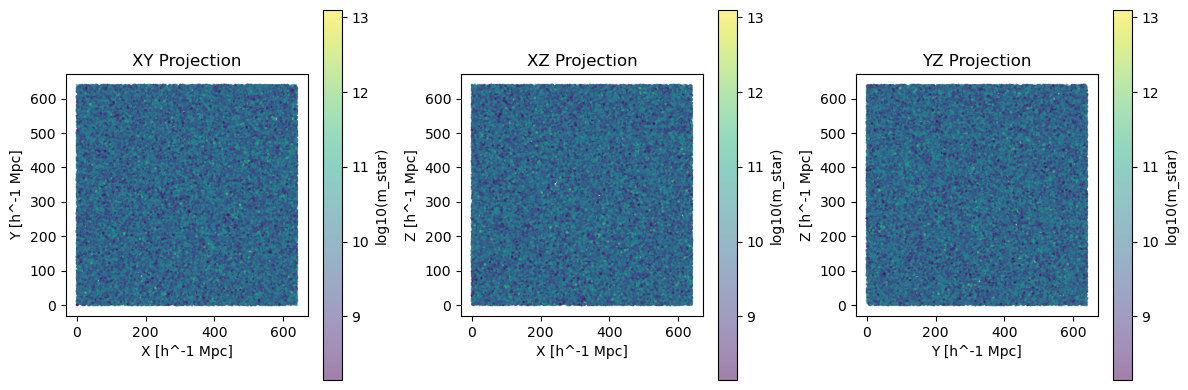

/tmp/ipykernel_3986/1632966281.py:57: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


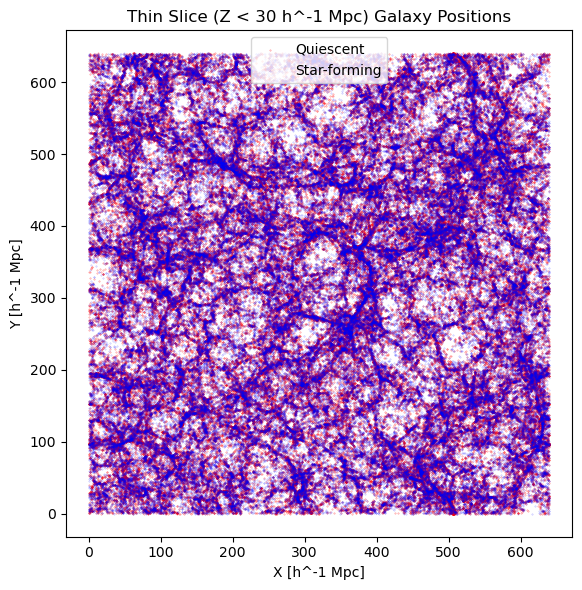

Mean number density: 0.034788318634033207 galaxies per (h^-1 Mpc)^3
Mean inter-galaxy separation: 3.0632952225274113 h^-1 Mpc


In [ ]:
# 1. Draw a random subsample of ~100,000 galaxies for plotting.
# 2. Plot the three 2D projections colour-coded by log10(m_star).
# 3. Plot a thin slice (z < 30 h^-1 Mpc), distinguishing SF and quiescent galaxies.
# 4. Print the mean number density and mean inter-galaxy separation.

sample = galaxies.sample(n=100000, random_state=42) 

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)

plt.scatter(sample['x'], sample['y'], c=sample['log10_ms'], cmap='viridis', s=1, alpha=0.5)
plt.xlabel('X [h^-1 Mpc]')
plt.ylabel('Y [h^-1 Mpc]')
plt.title('XY Projection')
plt.colorbar(label='log10(m_star)')
plt.gca().set_aspect('equal', adjustable='box')

plt.subplot(1, 3, 2)
plt.scatter(sample['x'], sample['z'], c=sample['log10_ms'], cmap='viridis', s=1, alpha=0.5)
plt.xlabel('X [h^-1 Mpc]')
plt.ylabel('Z [h^-1 Mpc]')
plt.title('XZ Projection')
plt.colorbar(label='log10(m_star)')
plt.gca().set_aspect('equal', adjustable='box')

plt.subplot(1, 3, 3)
plt.scatter(sample['y'], sample['z'], c=sample['log10_ms'], cmap='viridis', s=1, alpha=0.5)
plt.xlabel('Y [h^-1 Mpc]')
plt.ylabel('Z [h^-1 Mpc]')
plt.title('YZ Projection')
plt.colorbar(label='log10(m_star)')
plt.gca().set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()

# ---------

slice_mask = galaxies['z'] < 30.0
galaxies_slice = galaxies[slice_mask]

plt.figure(figsize=(6, 6))

plt.scatter(galaxies_slice[~galaxies_slice['is_sf']]['x'], galaxies_slice[~galaxies_slice['is_sf']]['y'], 
            c='red', s=0.1, alpha=0.5, label='Quiescent')

plt.scatter(galaxies_slice[galaxies_slice['is_sf']]['x'], galaxies_slice[galaxies_slice['is_sf']]['y'], 
            c='blue', s=0.1, alpha=0.3, label='Star-forming')

plt.xlabel('X [h^-1 Mpc]')
plt.ylabel('Y [h^-1 Mpc]')
plt.title('Thin Slice (Z < 30 h^-1 Mpc) Galaxy Positions')
plt.gca().set_aspect('equal', adjustable='box')
plt.legend()

plt.tight_layout()
plt.show()

# ------------

mean_number_density = len(galaxies) / BOX_SIZE**3
mean_inter_galaxy_separation = (BOX_SIZE**3 / len(galaxies))**(1/3)

print("Mean number density:", mean_number_density, "galaxies per (h^-1 Mpc)^3")
print("Mean inter-galaxy separation:", mean_inter_galaxy_separation, "h^-1 Mpc")

- Do the two populations trace the same structures? Are quiescent galaxies more concentrated in dense regions?
The two populations do trace similar large-scale structures, such as filaments and walls.
However, star-forming galaxies, controintuitively, tend to be more concentrated in dense regions, while quiescent galaxies are more evenly distributed throughout the cosmic web.

- Compare the mean inter-galaxy separation with the typical size of a galaxy group.
The mean inter-galaxy separation is approximately 3.06 h^-1 Mpc, which is larger than the typical size of a galaxy group,
which is on the order of 1 h^-1 Mpc.
This suggests that galaxy groups are relatively compact structures within the larger cosmic web, and that galaxies are
more closely packed within these groups.

#### TASK 2 — GALAXY POWER SPECTRUM FROM SCRATCH

In [ ]:
def ngp_assign(positions, box_size, n_grid):
    """
    Nearest Grid Point mass assignment.

    Parameters
    ----------
    positions : (N, 3) float array — comoving positions in h^-1 Mpc, range [0, box_size)
    box_size  : float — box side in h^-1 Mpc
    n_grid    : int   — grid cells per dimension

    Returns
    -------
    grid : (n_grid, n_grid, n_grid) float array — galaxy count field
    """
    
    # Steps:
    #   1. cell_size = box_size / n_grid
    #   2. Integer grid indices: ix = floor(x / cell_size) % n_grid  (and same for y, z)
    #   3. np.add.at(grid, (ix, iy, iz), 1)

    cell_size = box_size / n_grid

    # Inizializing the grid
    grid = np.zeros((n_grid, n_grid, n_grid), dtype=float)

    # Galaxy coordinates
    x, y, z = positions[:, 0], positions[:, 1], positions[:, 2]

    # Cell indices
    ix = np.floor(x / cell_size).astype(int) % n_grid
    iy = np.floor(y / cell_size).astype(int) % n_grid
    iz = np.floor(z / cell_size).astype(int) % n_grid

    # Increment the count in the corresponding cell
    np.add.at(grid, (ix, iy, iz), 1)

    return grid

In [11]:
def pk_from_grid(grid, box_size, n_halos=None, subtract_shot_noise=True):
    """
    Estimate the power spectrum from a 3-D count grid.

    Parameters
    ----------
    grid    : (N, N, N) array — galaxy count per cell
    box_size: float           — box side in h^-1 Mpc
    n_halos : int or None     — total galaxy count (for shot-noise subtraction)
    subtract_shot_noise : bool

    Returns
    -------
    k  : 1-D array  — shell-averaged wavenumber in h Mpc^-1
    Pk : 1-D array  — power spectrum in (h^-1 Mpc)^3
    Nk : 1-D array  — number of modes per shell
    """

    # Number of grid cells along each spatial direction
    n_grid = grid.shape[0]

    # Steps:
    #   1. delta = grid / grid.mean() - 1
    #   2. delta_k = np.fft.rfftn(delta)
    #   3. Pk_3d = (box_size**3 / n_grid**6) * np.abs(delta_k)**2
    #   4. Build 3-D K array using np.fft.fftfreq / rfftfreq:
    #        k_j = fftfreq(n_grid, d=box_size/n_grid) * 2*pi  (in h/Mpc)
    #   5. Bin Pk_3d into spherical shells with np.histogram; exclude K=0
    #   6. Subtract box_size**3 / n_halos if requested
    
    # Convert the galaxy count field into the density contrast
    delta = grid / grid.mean() - 1

     # Compute the 3D Fourier transform of the density contrast
    delta_k = np.fft.rfftn(delta)

    # Compute the 3D power spectrum:
    # P(k) is proportional to |delta(k)|^2.
    # The prefactor accounts for the FFT normalization and the box volume.
    Pk_3d = (box_size**3 / n_grid**6) * np.abs(delta_k)**2

    # Compute the Fourier-space wavenumbers in each spatial direction
    k_vals = np.fft.fftfreq(n_grid, d=box_size/n_grid) * 2 * np.pi

    # Build the 3D Fourier-space grid.
    # rfftfreq is used for the z-direction because rfftn stores
    # only the non-redundant positive-frequency modes.
    kx, ky, kz = np.meshgrid(k_vals, k_vals, np.fft.rfftfreq(n_grid, d=box_size/n_grid) * 2 * np.pi, indexing='ij')

    # Compute the magnitude of the wavevector
    k_mag = np.sqrt(kx**2 + ky**2 + kz**2)

    # Define bins in Fourier space to group modes with similar |k|
    k_bins = np.linspace(0, k_mag.max(), n_grid//2)

    # Compute the central k-value of each bin
    k = 0.5 * (k_bins[1:] + k_bins[:-1])

    # Count the number of Fourier modes in each spherical shell
    Nk = np.histogram(k_mag, bins=k_bins)[0]

    # Average the 3D power spectrum over spherical shells.
    # This produces the isotropic 1D power spectrum P(k).
    Pk = np.histogram(k_mag, bins=k_bins, weights=Pk_3d)[0] / Nk

    # Subtract the Poisson shot-noise contribution, if requested.
    if subtract_shot_noise and n_halos is not None:
        Pk -= box_size**3 / n_halos
    return k, Pk, Nk

# Use the NGP assignment scheme by default
def compute_pk(positions, box_size, n_grid=256, assign_func=None):
    """Convenience wrapper: positions array -> (k, Pk, Nk)."""
    if assign_func is None:
        assign_func = ngp_assign

    # Convert galaxy positions into a 3D count grid
    grid = assign_func(positions, box_size, n_grid)

    # Compute the power spectrum and subtract shot noise
    return pk_from_grid(grid, box_size, n_halos=len(positions))

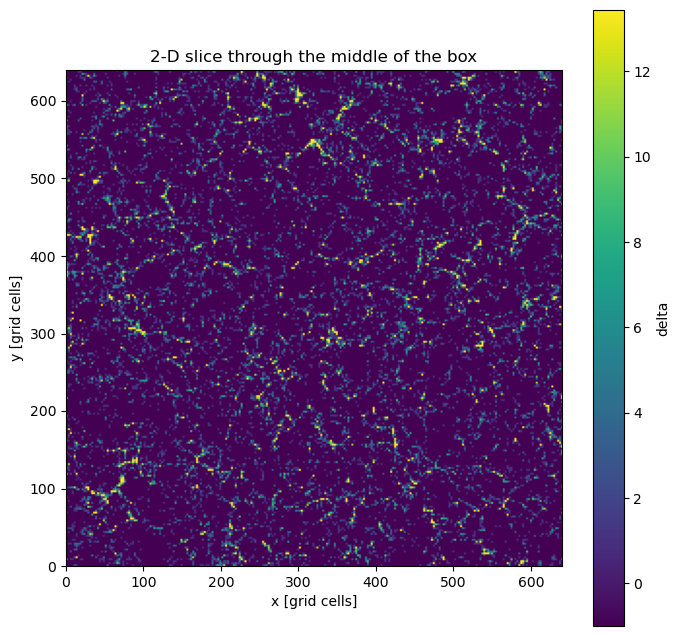

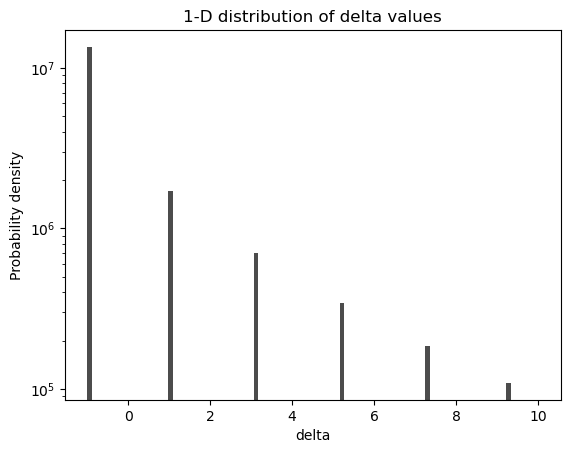

In [ ]:
MIN_MASS = 1e9    # h^-1 Msun
N_GRID   = 256

# 1. Select galaxies with m_star > MIN_MASS and extract positions as a (N,3) array.
# 2. Build the NGP density grid and compute delta = grid/mean - 1.
# 3. Plot a 2-D slice through the middle of the box.
# 4. Plot the 1-D distribution of delta values.

mass_mask = galaxies['m_star'] > MIN_MASS
positions = galaxies.loc[mass_mask, ['x', 'y', 'z']].values

grid = ngp_assign(positions, box_size=BOX_SIZE, n_grid=N_GRID)
delta = grid / grid.mean() - 1 # overdensity field

plt.figure(figsize=(8, 8))

plt.imshow(delta[:, :, N_GRID//2], extent=[0, BOX_SIZE, 0, BOX_SIZE], origin='lower', cmap='viridis', vmin=-1, vmax=np.percentile(delta, 99))
plt.colorbar(label='delta')
plt.xlabel('x [grid cells]')
plt.ylabel('y [grid cells]')
plt.title('2-D slice through the middle of the box')
plt.show()

plt.hist(delta.flatten(), bins=100, range=(-1, 10), log=True, color='k', alpha=0.7)
plt.xlabel('delta')
plt.ylabel('Probability density')
plt.title('1-D distribution of delta values')
plt.show()

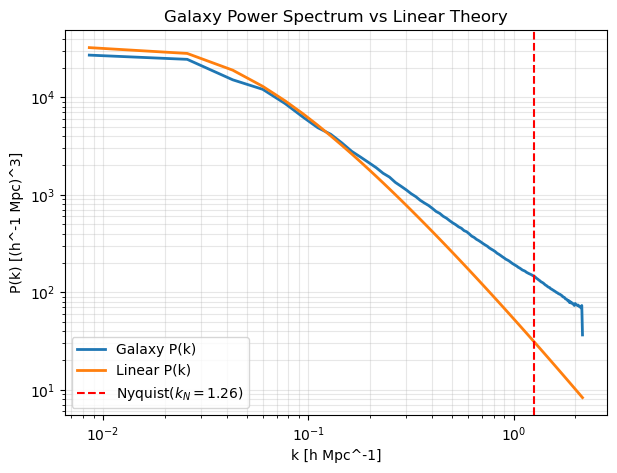

In [13]:
# Eisenstein & Hu (1998) transfer function — provided, do not modify

def _eh98_transfer(k, Omega_m=0.272, Omega_b=0.0456, h=0.704, T_cmb=2.7255):
    ombh2 = Omega_b * h**2;  ommh2 = Omega_m * h**2
    k_eq  = 7.46e-2 * ommh2 * (T_cmb / 2.7)**(-2)
    b1    = 0.313 * ommh2**(-0.419) * (1 + 0.607 * ommh2**0.674)
    b2    = 0.238 * ommh2**0.223
    z_d   = 1291 * ommh2**0.251 / (1 + 0.659 * ommh2**0.828) * (1 + b1 * ombh2**b2)
    alpha_c = (1 - 0.328 * np.log(431 * ommh2) * ombh2 / Omega_m
               + 0.38 * np.log(22.3 * ommh2) * (ombh2 / Omega_m)**2)
    beta_c  = 1 / (1 - 0.949 * ombh2 / Omega_m)**(-0.419
               * np.log(431 * ommh2) * ombh2 / Omega_m)
    q  = k / (13.41 * k_eq)
    C  = 14.2 / alpha_c + 386 / (1 + 69.9 * q**1.08)
    return np.log(np.e + 1.8*beta_c*q) / (np.log(np.e + 1.8*beta_c*q) + C*q**2)

def linear_pk_eh98(k, n_s=0.963, sigma8=0.809, Omega_m=0.272, Omega_b=0.0456, h=0.704):
    T   = _eh98_transfer(k, Omega_m, Omega_b, h)
    Pk  = k**n_s * T**2
    R8  = 8.0
    k_s = np.logspace(-4, 3, 2000)
    T_s = _eh98_transfer(k_s, Omega_m, Omega_b, h)
    W   = 3 * (np.sin(k_s*R8) - k_s*R8*np.cos(k_s*R8)) / (k_s*R8)**3
    sigma2 = np.trapezoid(k_s**n_s * T_s**2 * W**2 * k_s**2, k_s) / (2*np.pi**2)
    return sigma8**2 / sigma2 * Pk
    
# 1. Compute P(k) for galaxies with M* > 10^9 h^-1 Msun using compute_pk with N_GRID=256.
# 2. Compute linear P(k) with linear_pk_eh98.
# 3. Plot both on a log-log scale; mark the Nyquist frequency.

k, Pk, Nk = compute_pk(positions, box_size=BOX_SIZE, n_grid=N_GRID)

linear_Pk = linear_pk_eh98(k)

k_nyquist = np.pi * N_GRID / BOX_SIZE

plt.figure(figsize=(7, 5))

plt.loglog(k, Pk, label='Galaxy P(k)', lw=2)
plt.loglog(k, linear_Pk, label='Linear P(k)', lw=2)
plt.axvline(k_nyquist, color='red', linestyle='--', label=f'Nyquist($k_N={k_nyquist:.2f}$)')

plt.xlabel('k [h Mpc^-1]')
plt.ylabel('P(k) [(h^-1 Mpc)^3]')
plt.legend()
plt.title('Galaxy Power Spectrum vs Linear Theory')
plt.grid(True, which='both', alpha=0.3)

plt.show()

- Why must we subtract shot noise? What would the uncorrected P(k) look like at large k?
We must subtract shot noise because it represents the random fluctuations in the number of galaxies due to their discrete
nature. At large k (small scales), the uncorrected P(k) would be dominated by shot noise, leading to an overestimation of
the true clustering signal. This would result in a flat spectrum.

- At which k does the halo power spectrum exceed the linear theory? What causes this?
At about k ~ 0.15 h Mpc^-1, the halo power spectrum exceeds the linear theory. This is caused by non-linear gravitational
evolution, where the growth of structures leads to an increase in power on small scales compared to the predictions of
linear theory. Non-linear effects, such as the formation of galaxy clusters and filaments, contribute to this excess power.

- The BAO peak at k ~ 0.06 h Mpc^-1 — can you see it in the simulation?
Very close to k ~ 0.06 h Mpc^-1, there is a slight bump in the galaxy power spectrum.

#### TASK 3 — GALAXY BIAS: MASS CUTS AND STAR-FORMATION ACTIVITY

M* > 1.0e+09
  All galaxies : b = 0.94
  Star-forming : b = 0.74
  Quiescent    : b = 1.11


/tmp/ipykernel_3986/2240949860.py:39: RuntimeWarning: invalid value encountered in sqrt
  b_sf = np.sqrt(Pk_sf / np.interp(k_sf, k_lin, Pk_lin))


M* > 1.0e+10
  All galaxies : b = 1.04
  Star-forming : b = 0.83
  Quiescent    : b = 1.13
M* > 3.2e+10
  All galaxies : b = 1.18
  Star-forming : b = 1.38
  Quiescent    : b = 1.17
M* > 1.0e+11
  All galaxies : b = 1.43
  Star-forming : b = 1.81
  Quiescent    : b = 1.33


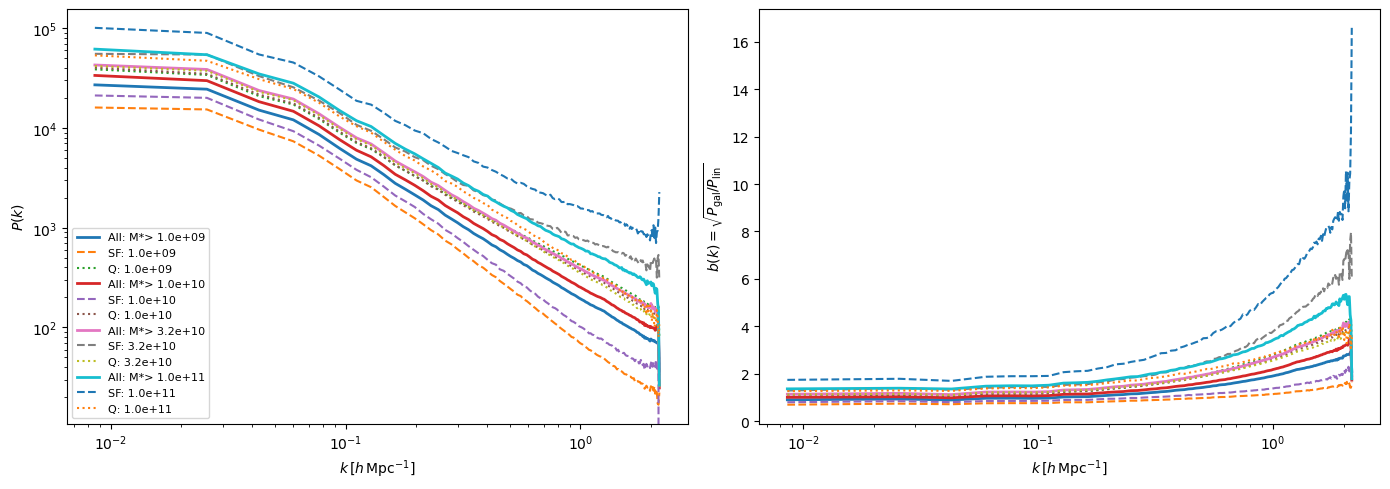

In [14]:
mass_cuts = [1e9, 1e10, 10**10.5, 1e11]

k_lin = np.logspace(-2, 1, 500)
Pk_lin = linear_pk_eh98(k_lin)

# Part A: for each mass cut, compute P(k) and plot.
# Part B: compute P(k) separately for star-forming and quiescent galaxies and plot.
# In a second panel, plot b(k) = sqrt(P_gal / P_lin) for all samples.
# Print the large-scale bias (k < 0.1 h/Mpc) for each selection.

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for mass_cut in mass_cuts:

    # Part A

    # Select galaxies
    selected = galaxies[galaxies["m_star"] > mass_cut]
    
    # Compute power spectra
    k, Pk, Nk = compute_pk(selected[["x", "y", "z"]].to_numpy(), box_size=BOX_SIZE, n_grid=N_GRID,)

    # Plot P(k)
    ax1.loglog(k, Pk, lw=2, label=f"All: M*> {mass_cut:.1e}")

    # Part B
    sf = selected[selected["sfr"] > 0]
    quiescent = selected[selected["sfr"] == 0]

    k_sf, Pk_sf, _ = compute_pk(sf[["x", "y", "z"]].to_numpy(), box_size=BOX_SIZE, n_grid=N_GRID,)
    k_q, Pk_q, _ = compute_pk(quiescent[["x", "y", "z"]].to_numpy(), box_size=BOX_SIZE, n_grid=N_GRID,)

    ax1.loglog(k_sf, Pk_sf, "--", label=f"SF: {mass_cut:.1e}")
    ax1.loglog(k_q, Pk_q, ":", label=f"Q: {mass_cut:.1e}")


    # Compute bias
    b = np.sqrt(Pk / np.interp(k, k_lin, Pk_lin))
    b_sf = np.sqrt(Pk_sf / np.interp(k_sf, k_lin, Pk_lin))
    b_q = np.sqrt(Pk_q / np.interp(k_q, k_lin, Pk_lin))

    ax2.semilogx(k, b, lw=2)
    ax2.semilogx(k_sf, b_sf, "--")
    ax2.semilogx(k_q, b_q, ":")

    # Large-scale bias
    b_large = np.mean(b[k < 0.1])
    b_sf_large = np.mean(b_sf[k_sf < 0.1])
    b_q_large = np.mean(b_q[k_q < 0.1])

    print(f"M* > {mass_cut:.1e}")
    print(f"  All galaxies : b = {b_large:.2f}")
    print(f"  Star-forming : b = {b_sf_large:.2f}")
    print(f"  Quiescent    : b = {b_q_large:.2f}")

# Formatting
ax1.set_xlabel(r"$k\,[h\,{\rm Mpc}^{-1}]$")
ax1.set_ylabel(r"$P(k)$")
ax1.legend(fontsize=8)

ax2.set_xlabel(r"$k\,[h\,{\rm Mpc}^{-1}]$")
ax2.set_ylabel(r"$b(k)=\sqrt{P_{\rm gal}/P_{\rm lin}}$")

plt.tight_layout()
plt.show()

- Are the bias values consistent with the expectation that more massive / more quiescent galaxies are more biased?
The bias values are consistent with the expectation that more massive galaxies are more strongly clustered and therefore
more biased. Increasing the stellar mass threshold leads to higher large-scale bias values, indicating that massive galaxies preferentially reside in more massive dark matter halos.
For the lowest mass thresholds (M* > 1.0e+09 and M* > 1.0e+10), quiescent galaxies show higher bias values than star-forming galaxies, consistent with the general tendency of quiescent galaxies to inhabit denser environments.
For the higher mass thresholds (M* > 3.2e+10 and M* > 1.0e+11), star-forming galaxies show higher bias values.
This difference may be related to the different stellar-mass distributions of the selected populations, since the high-mass
star-forming sample contains a significant fraction of very massive galaxies.
A fixed-stellar-mass comparison would be required to separate the effect of galaxy type from the mass dependence of
clustering.

#### OPTIONAL — CLOUD-IN-CELL (CIC) AND TRIANGULAR SHAPE CLOUD (TSC) SCHEMES

The NGP window suppresses power at small scales through convolution with a top-hat kernel in real space.
Higher-order schemes produce smoother windows and extend the reliable range of P(k) toward the Nyquist frequency.

k_Nyquist = 1.2566370614359172


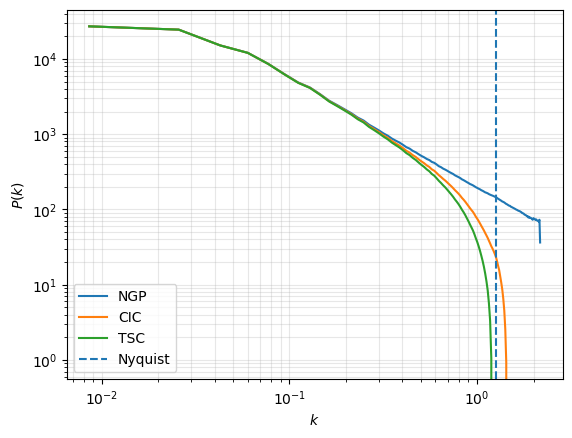

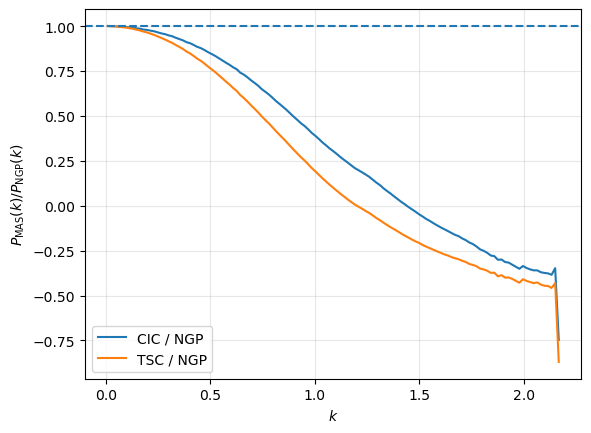

In [15]:
def cic_assign(positions, box_size, n_grid):
    '''
    Cloud-In-Cell: assign each galaxy to the 8 surrounding cells
    with weights proportional to the trilinear overlap volume.
    '''

    dx = box_size / n_grid
    x = positions / dx
    i = np.floor(x).astype(int)
    f = x - i

    grid = np.zeros((n_grid, n_grid, n_grid))

    for a in (0, 1):
        for b in (0, 1):
            for c in (0, 1):
                w = ((1 - f[:, 0]) if a == 0 else f[:, 0]) \
                  * ((1 - f[:, 1]) if b == 0 else f[:, 1]) \
                  * ((1 - f[:, 2]) if c == 0 else f[:, 2])

                idx = (i + [a, b, c]) % n_grid
                np.add.at(grid, tuple(idx.T), w)

    return grid

def tsc_assign(positions, box_size, n_grid):
    """
    Triangular Shape Cloud: use the quadratic kernel
    w(d) = 0.75 - d^2  for |d| < 0.5,
           0.5*(1.5-|d|)^2  for 0.5 <= |d| < 1.5
    applied over 27 neighbouring cells.
    """
    
    dx = box_size / n_grid
    x = (positions % box_size) / dx
    i = np.floor(x).astype(int)
    f = x - i

    grid = np.zeros((n_grid, n_grid, n_grid))

    for a in (-1, 0, 1):
        for b in (-1, 0, 1):
            for c in (-1, 0, 1):
                d = np.array([a, b, c])
                w = np.prod(np.where(np.abs(f - d) < 0.5, 0.75 - (f - d)**2, np.where(np.abs(f - d) < 1.5, 0.5 * (1.5 - np.abs(f - d))**2, 0)), axis=1)

                idx = (i + d) % n_grid
                np.add.at(grid, tuple(idx.T), w)

    return grid

# Compute P(k) with NGP, CIC, and TSC; plot them together.
# Plot the ratio P_MAS / P_NGP to quantify the window-function suppression.

results = {}

for name, assign_func in [("NGP", ngp_assign), ("CIC", cic_assign), ("TSC", tsc_assign),]:
    k, Pk, Nk = compute_pk(positions, BOX_SIZE, N_GRID, assign_func=assign_func)
    results[name] = (k, Pk)

    plt.loglog(k, Pk, label=name)

k_nyq = np.pi * N_GRID / BOX_SIZE
print("k_Nyquist =", k_nyq)

plt.axvline(k_nyq, linestyle="--", label="Nyquist")

plt.xlabel(r"$k$")
plt.ylabel(r"$P(k)$")
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

# Ratios relative to NGP

k_ngp, P_ngp = results["NGP"]

for name in ["CIC", "TSC"]:
    k, Pk = results[name]
    plt.plot(k, Pk / P_ngp, label=rf"{name} / NGP")

plt.axhline(1, linestyle="--")
plt.xlabel(r"$k$")
plt.ylabel(r"$P_{\rm MAS}(k) / P_{\rm NGP}(k)$")
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

- At which k do the three estimates diverge? How does the Nyquist suppression differ?
The three estimates agree well on large scales (small k). They start to diverge at k∼0.5 h Mpc^-1, where the mass-assignment
window functions become important. Near the Nyquist frequency, TSC shows the strongest suppression, followed by CIC, while
NGP has the weakest suppression. This is due to the increasing smoothing associated with the wider mass-assignment kernels.